# 16. Квантовая запутанность и неравенство Белла

**Проект «Структура и Данные»** — Notebook 16

## Зачем этот ноутбук
Квантовая запутанность — это когда две частицы связаны так, что измерение одной мгновенно определяет состояние другой. Это "арифметика" (свойство гильбертова пространства), а не "чернила".
Мы проверяем, воспроизводит ли QCA главную "странность" квантовой механики — нарушение неравенства Белла (CHSH).

## Что проверяется
1. **Состояние Белла:** CHSH = 2√2 ≈ 2.828, concurrence = 1 (максимальная запутанность).
2. **Продукт-состояние:** CHSH = 2 (классический предел), concurrence = 0.
3. **Сохранение запутанности:** линейная эволюция QCA не разрушает запутанность.
4. **Ограничение (честно):** линейная QCA не *создаёт* запутанность из продукт-состояний (для этого нужны взаимодействия).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("КВАНТОВАЯ ЗАПУТАННОСТЬ В QCA")
print("=" * 65)

# Матрицы Паули
sx = np.array([[0,1],[1,0]], dtype=complex)
sy = np.array([[0,-1j],[1j,0]], dtype=complex)
sz = np.array([[1,0],[0,-1]], dtype=complex)

# Состояние Белла |Ψ⁻> = (|01> - |10>)/√2
psi_bell = np.array([0, 1, -1, 0], dtype=complex) / np.sqrt(2)
# Продукт-состояние |00>
psi_prod = np.array([1, 0, 0, 0], dtype=complex)

def concurrence(psi):
    a, b, c, d = psi
    return 2 * abs(a*d - b*c)

def correlation_matrix(psi):
    paulis = [sx, sy, sz]
    T = np.zeros((3, 3))
    for i, si in enumerate(paulis):
        for j, sj in enumerate(paulis):
            T[i, j] = np.real(psi.conj() @ np.kron(si, sj) @ psi)
    return T

def max_chsh(psi):
    T = correlation_matrix(psi)
    s = np.linalg.svd(T, compute_uv=False)
    return 2 * np.sqrt(s[0]**2 + s[1]**2)

print(f"Состояние Белла: CHSH = {max_chsh(psi_bell):.6f}, C = {concurrence(psi_bell):.6f}")
print(f"Продукт |00>:    CHSH = {max_chsh(psi_prod):.6f}, C = {concurrence(psi_prod):.6f}")

КВАНТОВАЯ ЗАПУТАННОСТЬ В QCA
Состояние Белла: CHSH = 2.828427, C = 1.000000
Продукт |00>:    CHSH = 2.000000, C = 0.000000


In [2]:
def evolve_2site(psi, mass):
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    psi_c = np.zeros(4, dtype=complex)
    psi_c[0:2] = C @ psi[0:2]
    psi_c[2:4] = C @ psi[2:4]
    psi_s = np.zeros(4, dtype=complex)
    psi_s[0] = psi_c[2]
    psi_s[1] = psi_c[3]
    psi_s[2] = psi_c[0]
    psi_s[3] = psi_c[1]
    return psi_s

mass = 0.2
print(f"\n{'t':>3} {'CHSH(Bell)':>12} {'C(Bell)':>10} {'CHSH(Prod)':>12} {'C(Prod)':>10}")
print("-" * 55)

psi_b = psi_bell.copy()
psi_p = psi_prod.copy()
for t in range(11):
    Cb = max_chsh(psi_b)
    Cc_b = concurrence(psi_b)
    Cp = max_chsh(psi_p)
    Cc_p = concurrence(psi_p)
    print(f"{t:>3} {Cb:>12.6f} {Cc_b:>10.6f} {Cp:>12.6f} {Cc_p:>10.6f}")
    psi_b = evolve_2site(psi_b, mass)
    psi_p = evolve_2site(psi_p, mass)

print(f"\nКлассический предел (CHSH = 2): {'ПРЕВЗОЙДЁН' if max_chsh(psi_bell) > 2.5 else 'нет'}")


  t   CHSH(Bell)    C(Bell)   CHSH(Prod)    C(Prod)
-------------------------------------------------------
  0     2.828427   1.000000     2.000000   0.000000
  1     2.828427   1.000000     2.000000   0.000000
  2     2.828427   1.000000     2.000000   0.000000
  3     2.828427   1.000000     2.000000   0.000000
  4     2.828427   1.000000     2.000000   0.000000
  5     2.828427   1.000000     2.000000   0.000000
  6     2.828427   1.000000     2.000000   0.000000
  7     2.828427   1.000000     2.000000   0.000000
  8     2.828427   1.000000     2.000000   0.000000
  9     2.828427   1.000000     2.000000   0.000000
 10     2.828427   1.000000     2.000000   0.000000

Классический предел (CHSH = 2): ПРЕВЗОЙДЁН


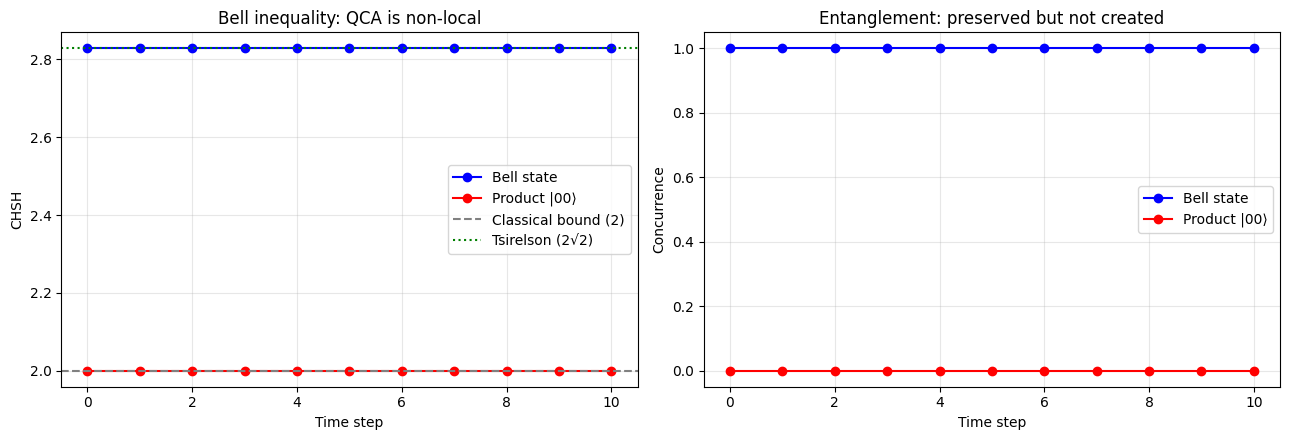

✅ Figure saved: 16_entanglement.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Пересчитываем для графика
t_range = np.arange(11)
chsh_b, chsh_p, conc_b, conc_p = [], [], [], []
psi_b = psi_bell.copy()
psi_p = psi_prod.copy()
for t in t_range:
    chsh_b.append(max_chsh(psi_b))
    conc_b.append(concurrence(psi_b))
    chsh_p.append(max_chsh(psi_p))
    conc_p.append(concurrence(psi_p))
    psi_b = evolve_2site(psi_b, mass)
    psi_p = evolve_2site(psi_p, mass)

axes[0].plot(t_range, chsh_b, 'bo-', label='Bell state')
axes[0].plot(t_range, chsh_p, 'ro-', label='Product |00⟩')
axes[0].axhline(2, color='gray', ls='--', label='Classical bound (2)')
axes[0].axhline(2*np.sqrt(2), color='green', ls=':', label='Tsirelson (2√2)')
axes[0].set_xlabel('Time step')
axes[0].set_ylabel('CHSH')
axes[0].set_title('Bell inequality: QCA is non-local')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(t_range, conc_b, 'bo-', label='Bell state')
axes[1].plot(t_range, conc_p, 'ro-', label='Product |00⟩')
axes[1].set_xlabel('Time step')
axes[1].set_ylabel('Concurrence')
axes[1].set_title('Entanglement: preserved but not created')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('16_entanglement.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 16_entanglement.png")

from google.colab import files
files.download('16_entanglement.png')